# **Authors**

*   Kumar Jayant
*   Dhruv Lalani

# **Notions of distance - Part 2**


Import required packages

In [17]:
# Import necessary libraries
import pandas as pd
import numpy as np
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.metrics.pairwise import pairwise_distances
# from ydata_profiling import ProfileReport
from sklearn.metrics.pairwise import pairwise_distances, cosine_similarity
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import entropy
from scipy.stats import norm, entropy
from scipy.stats import chi2
from sklearn.covariance import MinCovDet, EllipticEnvelope
from sklearn.metrics.pairwise import pairwise_distances


import warnings
# Suppress all warnings completely
warnings.filterwarnings('ignore')

##### Step 1: Data Preprocessing to ready the data for analysis

1. Ingest the ola dataset.
2. Data profiling
3. Data cleansing (dropping features not needed for analysis)
4. Data imputation
5. Short Description of the final features for familiarity with the dataset


Ingesting the dataset

**Mahalanobis distance**

To explain Mahalanobis, let us start with a synthetic date set of 300 rides, with 2 features only distance & fare

In [3]:
# 1. Simulate 300 normal rides: fare rises with distance
rng = np.random.default_rng(42)
km = rng.uniform(1, 40, 300)
fare = 40 + 18 * km + rng.normal(0, 40, 300)
rides = pd.DataFrame({'Ride_Distance_km': km, 'Booking_Value_INR': fare})


In [4]:
# 2. Fit a robust covariance "envelope" around normal behaviour
envelope = EllipticEnvelope(contamination=0.01, random_state=42)
envelope.fit(rides)

EllipticEnvelope(contamination=0.01, random_state=42)

In [5]:
# 3. Score two new rides with the same fare
new_rides = pd.DataFrame({'Ride_Distance_km': [38, 2],
                          'Booking_Value_INR': [760, 760]},
                         index=['Ride B (airport)', 'Ride A (short hop)'])

In [6]:
# .mahalanobis() returns the SQUARED distance, so take the square root
new_rides['Mahalanobis'] = np.sqrt(envelope.mahalanobis(new_rides))
new_rides['Is_Anomaly'] = envelope.predict(
    new_rides[['Ride_Distance_km', 'Booking_Value_INR']]) == -1

print(new_rides.round(2))

                    Ride_Distance_km  Booking_Value_INR  Mahalanobis  \
Ride B (airport)                  38                760         1.99   
Ride A (short hop)                 2                760        21.29   

                    Is_Anomaly  
Ride B (airport)         False  
Ride A (short hop)        True  


In [7]:
# Load the data
file_path = "/content/ola.csv"
ola_df = pd.read_csv(file_path, encoding='ISO-8859-1')
ola_df.head()

,Customer ID,Vehicle Type,Pickup Location,Drop Location,Avg VTAT,Avg CTAT,Booking Value,Payment Method,Ride Distance,Driver Ratings,Customer Rating
0,329258,Auto,Area-3,Area-2,5.42,18.46,868.06,Wallet,28.5,4.4,4.4
1,201414,Mini,Area-7,Area-6,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,301629,Bike,Area-40,Area-24,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,319684,Prime Sedan,Area-11,Area-24,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,330283,Bike,Area-41,Area-45,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [9]:
ola_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 49999 entries, 0 to 49998
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Customer ID      49999 non-null  int64  
 1   Vehicle Type     49999 non-null  object 
 2   Pickup Location  49999 non-null  object 
 3   Drop Location    49999 non-null  object 
 4   Avg VTAT         33484 non-null  float64
 5   Avg CTAT         33484 non-null  float64
 6   Booking Value    33484 non-null  float64
 7   Payment Method   33484 non-null  object 
 8   Ride Distance    33484 non-null  float64
 9   Driver Ratings   33484 non-null  float64
 10  Customer Rating  33484 non-null  float64
dtypes: float64(6), int64(1), object(4)
memory usage: 4.2+ MB


In [10]:
# convert Customer ID to object datatype
ola_df['Customer ID'] = ola_df['Customer ID'].astype(str)

In [11]:
ola_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 49999 entries, 0 to 49998
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Customer ID      49999 non-null  object 
 1   Vehicle Type     49999 non-null  object 
 2   Pickup Location  49999 non-null  object 
 3   Drop Location    49999 non-null  object 
 4   Avg VTAT         33484 non-null  float64
 5   Avg CTAT         33484 non-null  float64
 6   Booking Value    33484 non-null  float64
 7   Payment Method   33484 non-null  object 
 8   Ride Distance    33484 non-null  float64
 9   Driver Ratings   33484 non-null  float64
 10  Customer Rating  33484 non-null  float64
dtypes: float64(6), object(5)
memory usage: 4.2+ MB


**Data Imputation**

The following fields will be imputed for missing data.

**Numerical fields**

1. Avg VTAT
2. Avg CTAT
3. Booking Value
4. Ride Distance
5. Driver Ratings
6. Customer Rating

Logic for imputation - If there are multiple customer IDs for these fields then average of the customer IDs will be used for imputation else the previous row data shall be rolled over.

**Categorical field**

1. Payment Method

Logic for imputation - If there are multiple customer IDs for this field then max instance of the customer IDs will be used for imputation else the previous row data shall be rolled over.

In [12]:
# Imputing numerical features

ola_df['Avg VTAT'] = ola_df['Avg VTAT'].fillna(ola_df.groupby('Customer ID')['Avg VTAT'].transform('mean'))
ola_df['Avg VTAT'] = ola_df['Avg VTAT'].ffill().bfill()

ola_df['Avg CTAT'] = ola_df['Avg CTAT'].fillna(ola_df.groupby('Customer ID')['Avg CTAT'].transform('mean'))
ola_df['Avg CTAT'] = ola_df['Avg CTAT'].ffill().bfill()

ola_df['Booking Value'] = ola_df['Booking Value'].fillna(ola_df.groupby('Customer ID')['Booking Value'].transform('mean'))
ola_df['Booking Value'] = ola_df['Booking Value'].ffill().bfill()

ola_df['Ride Distance'] = ola_df['Ride Distance'].fillna(ola_df.groupby('Customer ID')['Ride Distance'].transform('mean'))
ola_df['Ride Distance'] = ola_df['Ride Distance'].ffill().bfill()

ola_df['Driver Ratings'] = ola_df['Driver Ratings'].fillna(ola_df.groupby('Customer ID')['Driver Ratings'].transform('mean'))
ola_df['Driver Ratings'] = ola_df['Driver Ratings'].ffill().bfill()

ola_df['Customer Rating'] = ola_df['Customer Rating'].fillna(ola_df.groupby('Customer ID')['Customer Rating'].transform('mean'))
ola_df['Customer Rating'] = ola_df['Customer Rating'].ffill().bfill()

In [13]:
# Imputing categorical feature

# Imputing categorical feature safely
ola_df['Payment Method'] = ola_df['Payment Method'].fillna(
    ola_df.groupby('Customer ID')['Payment Method'].transform(
        lambda x: x.mode().iloc[0] if not x.mode().empty else np.nan
    )
)
ola_df['Payment Method'] = ola_df['Payment Method'].ffill().bfill()

In [14]:
ola_df.head()

,Customer ID,Vehicle Type,Pickup Location,Drop Location,Avg VTAT,Avg CTAT,Booking Value,Payment Method,Ride Distance,Driver Ratings,Customer Rating
0,329258,Auto,Area-3,Area-2,5.42,18.46,868.06,Wallet,28.5,4.4,4.4
1,201414,Mini,Area-7,Area-6,5.42,18.46,868.06,Wallet,28.5,4.4,4.4
2,301629,Bike,Area-40,Area-24,5.42,18.46,868.06,Wallet,28.5,4.4,4.4
3,319684,Prime Sedan,Area-11,Area-24,5.42,18.46,868.06,Wallet,28.5,4.4,4.4
4,330283,Bike,Area-41,Area-45,5.42,18.46,868.06,Wallet,28.5,4.4,4.4


Now we will consolidate the data at unique customer ID level.

Remember we are trying to find distance or similarity among customers, hence it is essential that we have one unique customer ID row

In [15]:
numeric_cols = [
    'Avg VTAT', 'Avg CTAT', 'Booking Value',
    'Ride Distance', 'Driver Ratings', 'Customer Rating'
]
for col in numeric_cols:
    # errors='coerce' turns any accidental text strings or bad formatting into real NaNs
    ola_df[col] = pd.to_numeric(ola_df[col], errors='coerce')


categorical_cols = ['Vehicle Type', 'Pickup Location', 'Drop Location', 'Payment Method']
for col in categorical_cols:
    ola_df[col] = ola_df[col].astype(str)

ola_df[categorical_cols] = ola_df[categorical_cols].replace({'nan': np.nan, 'None': np.nan})

final_aggregation_rules = {

    # Numerical features
    'Avg VTAT': 'mean',
    'Avg CTAT': 'mean',
    'Booking Value': 'mean',
    'Ride Distance': 'mean',
    'Driver Ratings': 'mean',
    'Customer Rating': 'mean',

    # Categorical features (Using custom lambda to safely extract the mode)
    'Vehicle Type': lambda x: x.mode().iloc[0] if not x.mode().empty else np.nan,
    'Pickup Location': lambda x: x.mode().iloc[0] if not x.mode().empty else np.nan,
    'Drop Location': lambda x: x.mode().iloc[0] if not x.mode().empty else np.nan,
    'Payment Method': lambda x: x.mode().iloc[0] if not x.mode().empty else np.nan,
}

df_ola_cust_profile = ola_df.groupby('Customer ID').agg(final_aggregation_rules)

# Ensuring that categorical variables in no case carry nan values
categorical_cols = ['Vehicle Type', 'Pickup Location', 'Drop Location', 'Payment Method']
df_ola_cust_profile[categorical_cols] = df_ola_cust_profile[categorical_cols].ffill().bfill()

# Resetting the index
df_ola_cust_profile = df_ola_cust_profile.reset_index()

In [16]:
df_ola_cust_profile.head()

,Customer ID,Avg VTAT,Avg CTAT,Booking Value,Ride Distance,Driver Ratings,Customer Rating,Vehicle Type,Pickup Location,Drop Location,Payment Method
0,100001,17.83,20.58,278.52,26.48,3.9,4.1,Auto,Area-36,Area-40,UPI
1,100059,12.73,7.50,795.82,48.41,3.9,4.2,Mini,Area-4,Area-39,UPI
2,100090,10.14,19.37,240.53,3.17,4.7,4.7,Auto,Area-44,Area-17,UPI
3,100097,12.19,10.27,678.06,18.18,3.2,3.5,Mini,Area-8,Area-39,UPI
4,100119,8.57,25.09,1458.82,17.10,3.4,3.1,Auto,Area-40,Area-45,UPI


In [18]:
# preserve original dataframe before dropping Customer ID
original_df = df_ola_cust_profile.copy()

In [19]:
# Drop Customer ID
df_ola_cust_profile.drop(columns=['Customer ID'], inplace=True)

In [20]:
df_ola_cust_profile.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48669 entries, 0 to 48668
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Avg VTAT         48669 non-null  float64
 1   Avg CTAT         48669 non-null  float64
 2   Booking Value    48669 non-null  float64
 3   Ride Distance    48669 non-null  float64
 4   Driver Ratings   48669 non-null  float64
 5   Customer Rating  48669 non-null  float64
 6   Vehicle Type     48669 non-null  object 
 7   Pickup Location  48669 non-null  object 
 8   Drop Location    48669 non-null  object 
 9   Payment Method   48669 non-null  object 
dtypes: float64(6), object(4)
memory usage: 3.7+ MB


Now we will calculate Mahalanobis distance from 2 methods.

Method 1: robust Mahalanobis + chi-square cut-off. Useful when data has to be flagged in real time and arrives in fine grain

Method 2: EllipticEnvelope takes a fixed number of data points or customer and flags them as outlier. This is more useful in batch methods, say 1,000,000 data points have to be checked overnight.

In [21]:
# isolate numerical columns from the Ola dataset and save them in X

num_cols = ['Avg VTAT', 'Avg CTAT', 'Booking Value',
            'Ride Distance', 'Driver Ratings', 'Customer Rating']
X = df_ola_cust_profile[num_cols]

In [23]:
# Check correlation
print(X.corr().round(0))

                 Avg VTAT  Avg CTAT  Booking Value  Ride Distance  \
Avg VTAT              1.0       0.0           -0.0           -0.0   
Avg CTAT              0.0       1.0            0.0           -0.0   
Booking Value        -0.0       0.0            1.0            0.0   
Ride Distance        -0.0      -0.0            0.0            1.0   
Driver Ratings        0.0      -0.0           -0.0           -0.0   
Customer Rating       0.0      -0.0           -0.0           -0.0   

                 Driver Ratings  Customer Rating  
Avg VTAT                    0.0              0.0  
Avg CTAT                   -0.0             -0.0  
Booking Value              -0.0             -0.0  
Ride Distance              -0.0             -0.0  
Driver Ratings              1.0             -0.0  
Customer Rating            -0.0              1.0  


There is hardly any correlation between variables, this implies that the data is more spherical than elliptical hence Mahalanobis will generalise towards Euclidean distance and both the results will be equal.

In [26]:
# Method 1: robust Mahalanobis + chi-square cut-off. Useful when data has to be flagged in real time and arrives in fine grain
mcd = MinCovDet(random_state=42).fit(X)
dist = np.sqrt(mcd.mahalanobis(X))            # .mahalanobis() returns the squared distance
cut_off = np.sqrt(chi2.ppf(0.975, df=len(num_cols)))
print(f'cut_off: {cut_off}')
print('Approach 1 flags:', (dist > cut_off).sum())

cut_off: 3.801233396602729
Approach 1 flags: 9


In [27]:
# Method 2: EllipticEnvelope takes a fixed number of data points or customer and flags them as outlier.
env = EllipticEnvelope(contamination=0.01, random_state=42).fit(X)
print('Approach 2 flags:', (env.predict(X) == -1).sum())

Approach 2 flags: 487


In [30]:
# Pairwise Mahalanobis for 100 sampled customers to go easy on compute cycles
VI = np.linalg.inv(np.cov(X.values, rowvar=False))     # inverse covariance from ALL customers
sample = X.sample(n=100, random_state=42)
dist_matrix = pairwise_distances(sample, metric='mahalanobis', VI=VI)
print(dist_matrix)

[[0.         3.76617085 3.6480164  ... 3.41625591 4.20333355 2.92618486]
 [3.76617085 0.         2.65040983 ... 2.47191664 2.67766302 3.66278837]
 [3.6480164  2.65040983 0.         ... 3.20637228 3.1323268  3.01336458]
 ...
 [3.41625591 2.47191664 3.20637228 ... 0.         3.41541189 3.55608656]
 [4.20333355 2.67766302 3.1323268  ... 3.41541189 0.         4.75504244]
 [2.92618486 3.66278837 3.01336458 ... 3.55608656 4.75504244 0.        ]]


**KL Divergence**

Approach adopted: The ola dataset has been horizontally between P & Q and then the divergence has been calculated by-features.

In [31]:
def audit_ola_data_drift(df, cat_cols, num_cols, bins=10, epsilon=1e-6):
    """
    Splits an OLA/Uber dataset horizontally into top half (P) and bottom half (Q)
    after sorting chronologically, then calculates KL Divergence feature-by-feature.
    """


    # Count total rows and find the midpoint for a clean 50/50 horizontal split
    total_rows = len(df)
    midpoint = total_rows // 2

    # Top half becomes df_planned (Baseline P), bottom half becomes df_actual (Actual Q)
    df_planned = df.iloc[:midpoint]
    df_actual = df.iloc[midpoint:]

    results = {}

    # --- AUDIT CATEGORICAL COLUMNS ---
    for col in cat_cols:
        if col in df.columns:
            p = df_planned[col].value_counts(normalize=True)
            q = df_actual[col].value_counts(normalize=True)

            # Align categories so both series match
            p, q = p.align(q, fill_value=0)

            # Smooth and normalize
            p_arr = (p.values + epsilon) / (p.values + epsilon).sum()
            q_arr = (q.values + epsilon) / (q.values + epsilon).sum()

            results[col] = entropy(p_arr, q_arr)

    # --- AUDIT CONTINUOUS COLUMNS ---
    for col in num_cols:
        if col in df.columns:
            # Use combined min/max across both splits to set stable histogram bin edges
            min_val = min(df_planned[col].min(), df_actual[col].min())
            max_val = max(df_planned[col].max(), df_actual[col].max())
            bin_edges = np.linspace(min_val, max_val, bins + 1)

            # Histogram counts
            p_counts, _ = np.histogram(df_planned[col].dropna(), bins=bin_edges)
            q_counts, _ = np.histogram(df_actual[col].dropna(), bins=bin_edges)

            # Smooth and normalize to probabilities
            p_arr = (p_counts + epsilon) / (p_counts + epsilon).sum()
            q_arr = (q_counts + epsilon) / (q_counts + epsilon).sum()

            results[col] = entropy(p_arr, q_arr)

    return pd.Series(results, name="KL_Divergence_Drift_Score")

In [32]:
cat_cols = ['Vehicle Type', 'Pickup Location', 'Drop Location', 'Payment Method']
num_cols = ['Avg VTAT', 'Avg CTAT', 'Booking Value', 'Ride Distance', 'Driver Ratings', 'Customer Rating']


drift_report = audit_ola_data_drift(df_ola_cust_profile, cat_cols, num_cols)
print(drift_report.sort_values(ascending=False))

Pickup Location    0.002166
Drop Location      0.001427
Avg CTAT           0.000536
Ride Distance      0.000403
Customer Rating    0.000401
Driver Ratings     0.000376
Booking Value      0.000184
Payment Method     0.000178
Avg VTAT           0.000148
Vehicle Type       0.000097
Name: KL_Divergence_Drift_Score, dtype: float64


In [33]:
def plot_numerical_normal_curves(df, num_cols, bins=10, epsilon=1e-6):
    """
    Sorts dataframe chronologically, splits horizontally into P (top half) and Q (bottom half),
    and plots normal curves for continuous numerical features.
    """
    midpoint = len(df) // 2
    df_p = df.iloc[:midpoint]
    df_q = df.iloc[midpoint:]

    # Setup grid layout (2 rows, 3 columns for 6 numerical features)
    fig, axes = plt.subplots(2, 3, figsize=(16, 9))
    axes_num = axes.flatten()

    for i, col in enumerate(num_cols):
        ax = axes_num[i]
        if col not in df.columns:
            continue

        # Fit parameters for normal distribution curves
        mu_p, std_p = df_p[col].mean(), df_p[col].std()
        mu_q, std_q = df_q[col].mean(), df_q[col].std()

        # Calculate exact binned KL divergence score for the title
        min_v = min(df_p[col].min(), df_q[col].min())
        max_v = max(df_p[col].max(), df_q[col].max())
        hist_bins = np.linspace(min_v, max_v, bins + 1)

        p_counts, _ = np.histogram(df_p[col].dropna(), bins=hist_bins)
        q_counts, _ = np.histogram(df_q[col].dropna(), bins=hist_bins)
        p_arr = (p_counts + epsilon) / (p_counts + epsilon).sum()
        q_arr = (q_counts + epsilon) / (q_counts + epsilon).sum()
        kl_score = entropy(p_arr, q_arr)

        # Generate normal curve lines
        x = np.linspace(min_v, max_v, 200)
        y_p = norm.pdf(x, mu_p, std_p if std_p > 0 else 1e-5)
        y_q = norm.pdf(x, mu_q, std_q if std_q > 0 else 1e-5)

        ax.plot(x, y_p, label='P (Top Half)', color='blue', linewidth=2)
        ax.plot(x, y_q, label='Q (Bottom Half)', color='orange', linestyle='--', linewidth=2)
        ax.fill_between(x, y_p, alpha=0.15, color='blue')
        ax.fill_between(x, y_q, alpha=0.15, color='orange')

        ax.set_title(f"{col}\nKL Divergence: {kl_score:.5f}", fontsize=10, fontweight='bold')
        ax.set_xlabel('Value', fontsize=9)
        ax.set_ylabel('Density', fontsize=9)
        ax.legend(loc='upper right', fontsize=8)
        ax.grid(True, linestyle=':', alpha=0.5)

    plt.suptitle('Numerical Features: P vs Q Normal Curve Comparisons', fontsize=14, fontweight='bold', y=1.02)
    plt.tight_layout()
    plt.savefig('numerical_features_drift.png', dpi=300)
    plt.show()

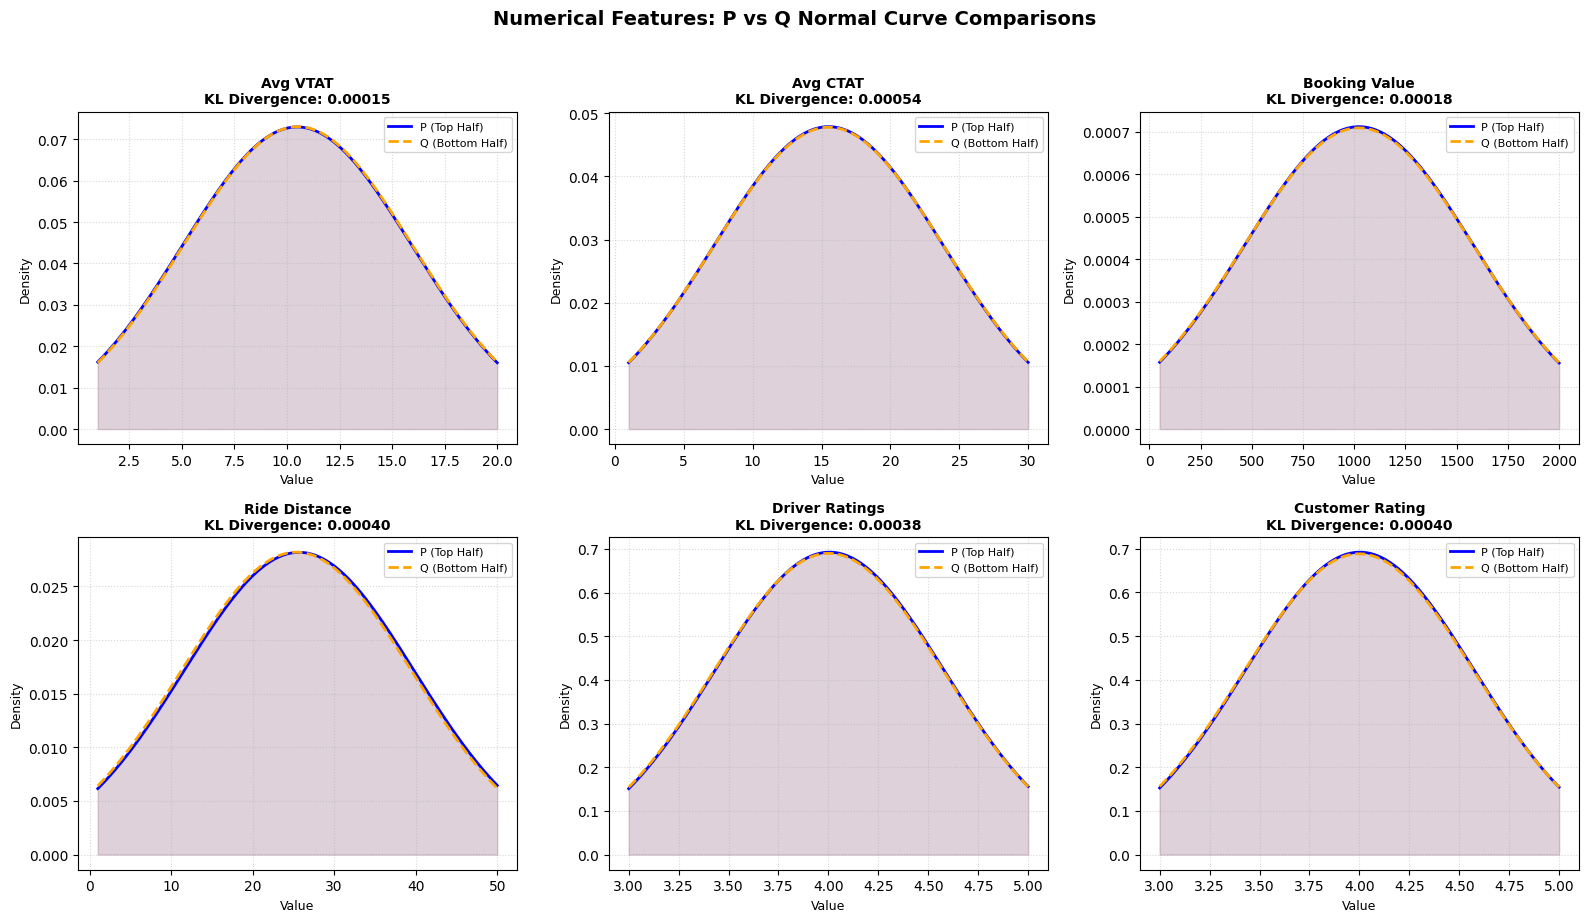

In [34]:
plot_numerical_normal_curves(df_ola_cust_profile, num_cols, bins=10, epsilon=1e-6)

Conclusion: For the features the D(kl) ~ 0 hence there is no difference in data distribution between the top and the bottom half

In [36]:
def plot_categorical_bar_charts(df, cat_cols, epsilon=1e-6):
    """
    Sorts dataframe chronologically, splits horizontally into P (top half) and Q (bottom half),
    and plots probability bar charts for categorical features.
    """
    midpoint = len(df) // 2
    df_p = df.iloc[:midpoint]
    df_q = df.iloc[midpoint:]

    fig_cat, axes_cat = plt.subplots(len(cat_cols), 1, figsize=(10, 4 * len(cat_cols)))
    if len(cat_cols) == 1:
        axes_cat = [axes_cat]

    for i, col in enumerate(cat_cols):
        ax = axes_cat[i]
        if col not in df.columns:
            continue

        # Get normalized value counts
        p = df_p[col].value_counts(normalize=True)
        q = df_q[col].value_counts(normalize=True)

        # Align indexes so categories match side-by-side
        p_df, q_df = p.align(q, fill_value=0)
        combined_df = pd.DataFrame({'P (Top)': p_df, 'Q (Bottom)': q_df})

        # Calculate KL divergence for title
        p_arr = (p_df.values + epsilon) / (p_df.values + epsilon).sum()
        q_arr = (q_df.values + epsilon) / (q_df.values + epsilon).sum()
        kl_score = entropy(p_arr, q_arr)

        # Limit cardinality to top 10 categories if there are too many unique values (e.g. Locations)
        if len(combined_df) > 10:
            combined_df = combined_df.sort_values(by='P (Top)', ascending=False).head(10)

        combined_df.plot(kind='bar', ax=ax, width=0.7, color=['blue', 'orange'])
        ax.set_title(f"Categorical Feature: {col} | KL Divergence: {kl_score:.5f}", fontsize=11, fontweight='bold')
        ax.set_ylabel('Probability Proportion', fontsize=9)
        ax.set_xlabel('Categories', fontsize=9)
        ax.tick_params(axis='x', rotation=30)
        ax.grid(axis='y', linestyle=':', alpha=0.5)
        ax.legend(loc='upper right', fontsize=9)

    plt.suptitle('Categorical Features: P vs Q Probability Distribution Shifts', fontsize=14, fontweight='bold', y=1.01)
    plt.tight_layout()
    plt.savefig('categorical_features_drift.png', dpi=300)
    plt.show()

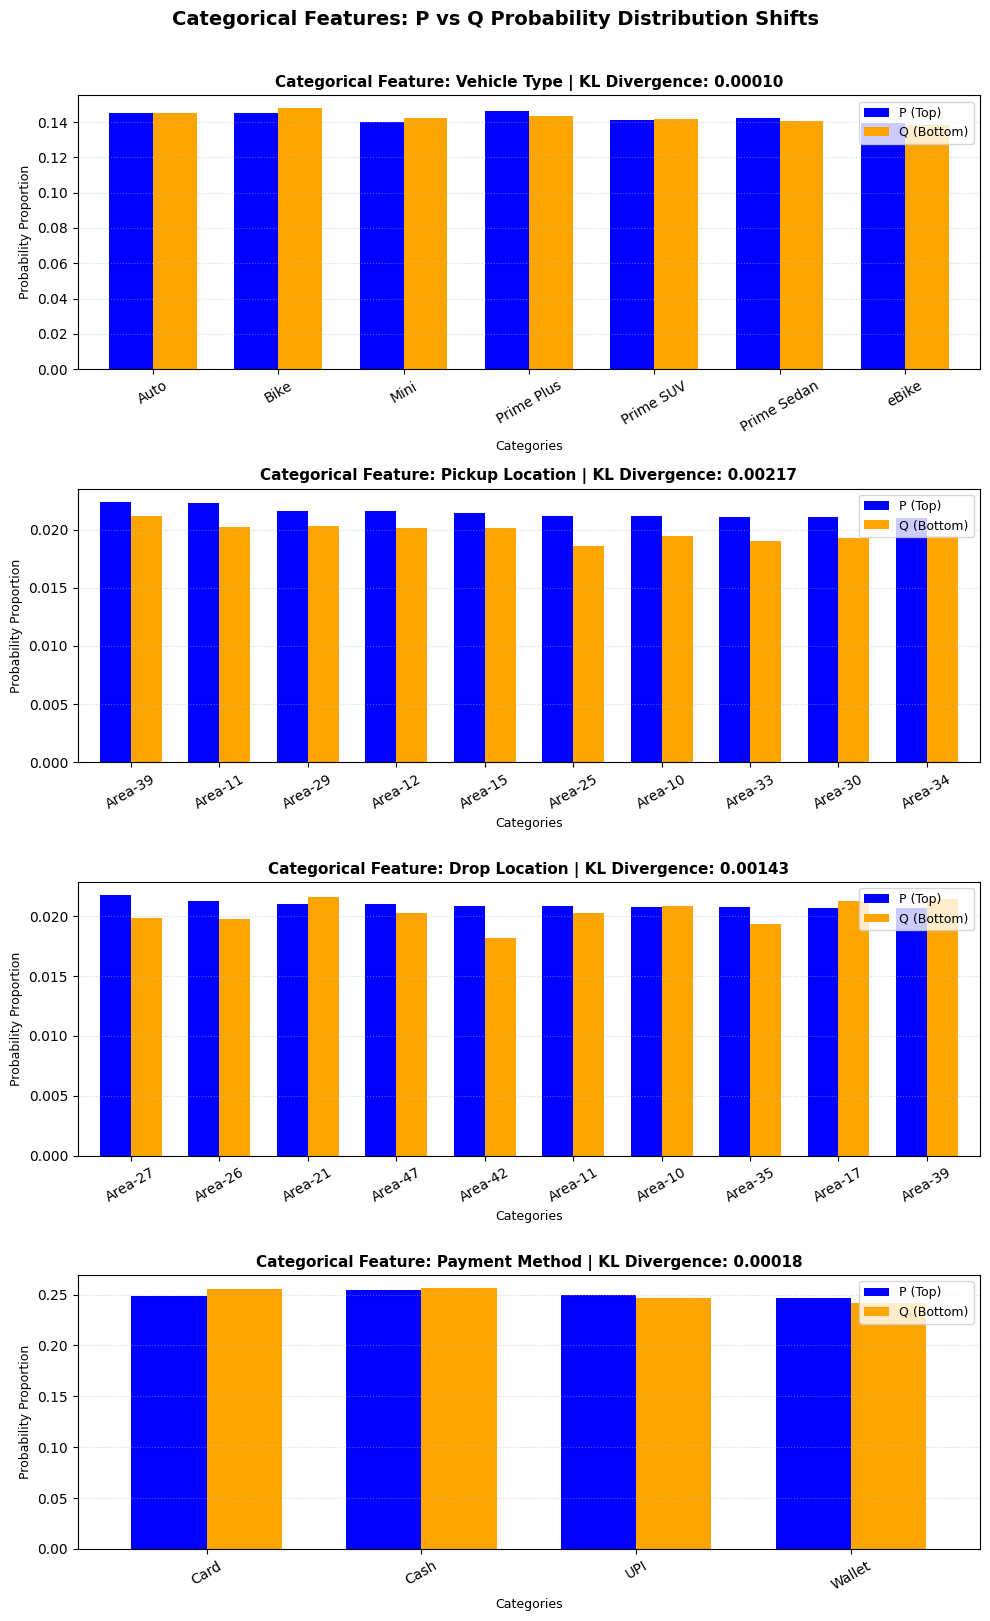

In [37]:
plot_categorical_bar_charts(df_ola_cust_profile, cat_cols, epsilon=1e-6)

**Bhattacharya Distance**

In [38]:
def audit_ola_bhattacharyya_drift(df, cat_cols, num_cols, bins=10):
    """
    Splits an OLA dataset horizontally into top half (P) and bottom half (Q)
    after sorting chronologically, then calculates Bhattacharyya Distance
    feature-by-feature WITHOUT epsilon smoothing.
    """

    # Count total rows and find the midpoint for a clean 50/50 horizontal split
    total_rows = len(df)
    midpoint = total_rows // 2

    # Top half becomes df_planned (Baseline P), bottom half becomes df_actual (Actual Q)
    df_planned = df.iloc[:midpoint]
    df_actual = df.iloc[midpoint:]

    results = {}

    # --- AUDIT CATEGORICAL COLUMNS ---
    for col in cat_cols:
        if col in df.columns:
            p = df_planned[col].value_counts(normalize=True)
            q = df_actual[col].value_counts(normalize=True)

            # Align categories so both series match (missing ones fill with 0)
            p, q = p.align(q, fill_value=0)

            # Bhattacharyya Coefficient: sum of square root of products (Raw, no smoothing)
            bc = np.sum(np.sqrt(p.values * q.values))

            # Safety floor strictly for complete zero overlap to avoid log(0) = -inf crash
            bc = max(bc, 1e-12)

            # Bhattacharyya Distance
            results[col] = -np.log(bc)

    # --- AUDIT CONTINUOUS COLUMNS ---
    for col in num_cols:
        if col in df.columns:
            # Use combined min/max across both splits to set stable histogram bin edges
            min_val = min(df_planned[col].min(), df_actual[col].min())
            max_val = max(df_planned[col].max(), df_actual[col].max())
            bin_edges = np.linspace(min_val, max_val, bins + 1)

            # Histogram counts
            p_counts, _ = np.histogram(df_planned[col].dropna(), bins=bin_edges)
            q_counts, _ = np.histogram(df_actual[col].dropna(), bins=bin_edges)

            # Convert counts directly to raw probabilities (no epsilon)
            p_arr = p_counts / p_counts.sum()
            q_arr = q_counts / q_counts.sum()

            # Bhattacharyya Coefficient
            bc = np.sum(np.sqrt(p_arr * q_arr))
            bc = max(bc, 1e-12)

            # Bhattacharyya Distance
            results[col] = -np.log(bc)

    return pd.Series(results, name="Bhattacharyya_Distance_Score")

In [39]:
cat_cols = ['Vehicle Type', 'Pickup Location', 'Drop Location', 'Payment Method']
num_cols = ['Avg VTAT', 'Avg CTAT', 'Booking Value', 'Ride Distance', 'Driver Ratings', 'Customer Rating']


drift_report_BD = audit_ola_bhattacharyya_drift(df_ola_cust_profile, cat_cols, num_cols)
print(drift_report_BD.sort_values(ascending=False))

Pickup Location    0.000543
Drop Location      0.000357
Avg CTAT           0.000134
Ride Distance      0.000101
Customer Rating    0.000101
Driver Ratings     0.000094
Booking Value      0.000046
Payment Method     0.000045
Avg VTAT           0.000037
Vehicle Type       0.000024
Name: Bhattacharyya_Distance_Score, dtype: float64


In [40]:
def plot_numerical_bhattacharyya_curves(df, num_cols, bins=10):
    """
    Sorts dataframe chronologically by time_col, splits horizontally into P (top half) and Q (bottom half),
    plots normal curves, and calculates the Bhattacharyya Distance for each continuous numerical feature.
    """
    # 1. Sort chronologically and split horizontally
    midpoint = len(df) // 2
    df_p = df.iloc[:midpoint]
    df_q = df.iloc[midpoint:]

    # Setup grid layout (2 rows, 3 columns for 6 numerical features)
    fig, axes = plt.subplots(2, 3, figsize=(16, 9))
    axes_num = axes.flatten()

    for i, col in enumerate(num_cols):
        ax = axes_num[i]
        if col not in df.columns:
            continue

        # Fit parameters for normal distribution curves
        mu_p, std_p = df_p[col].mean(), df_p[col].std()
        mu_q, std_q = df_q[col].mean(), df_q[col].std()

        # Calculate Bhattacharyya Distance via binned histograms (No epsilon smoothing)
        min_v = min(df_p[col].min(), df_q[col].min())
        max_v = max(df_p[col].max(), df_q[col].max())
        hist_bins = np.linspace(min_v, max_v, bins + 1)

        p_counts, _ = np.histogram(df_p[col].dropna(), bins=hist_bins)
        q_counts, _ = np.histogram(df_q[col].dropna(), bins=hist_bins)

        # Convert counts directly to raw probabilities
        p_arr = p_counts / p_counts.sum()
        q_arr = q_counts / q_counts.sum()

        # Bhattacharyya Coefficient: sum of square root of products
        bc = np.sum(np.sqrt(p_arr * q_arr))
        bc = max(bc, 1e-12)  # Safety floor to avoid log(0)

        # Bhattacharyya Distance using natural log (ln)
        bhatt_score = -np.log(bc)

        # Generate normal curve lines
        x = np.linspace(min_v, max_v, 200)
        y_p = norm.pdf(x, mu_p, std_p if std_p > 0 else 1e-5)
        y_q = norm.pdf(x, mu_q, std_q if std_q > 0 else 1e-5)

        ax.plot(x, y_p, label='P (Top Half)', color='blue', linewidth=2)
        ax.plot(x, y_q, label='Q (Bottom Half)', color='orange', linestyle='--', linewidth=2)
        ax.fill_between(x, y_p, alpha=0.15, color='blue')
        ax.fill_between(x, y_q, alpha=0.15, color='orange')

        # Title updated to reflect Bhattacharyya Distance
        ax.set_title(f"{col}\nBhattacharyya Distance: {bhatt_score:.5f}", fontsize=10, fontweight='bold')
        ax.set_xlabel('Value', fontsize=9)
        ax.set_ylabel('Density', fontsize=9)
        ax.legend(loc='upper right', fontsize=8)
        ax.grid(True, linestyle=':', alpha=0.5)

    plt.suptitle('Numerical Features: P vs Q Normal Curve Comparisons (Bhattacharyya Distance)', fontsize=14, fontweight='bold', y=1.02)
    plt.tight_layout()
    plt.savefig('numerical_features_bhattacharyya.png', dpi=300)
    plt.show()

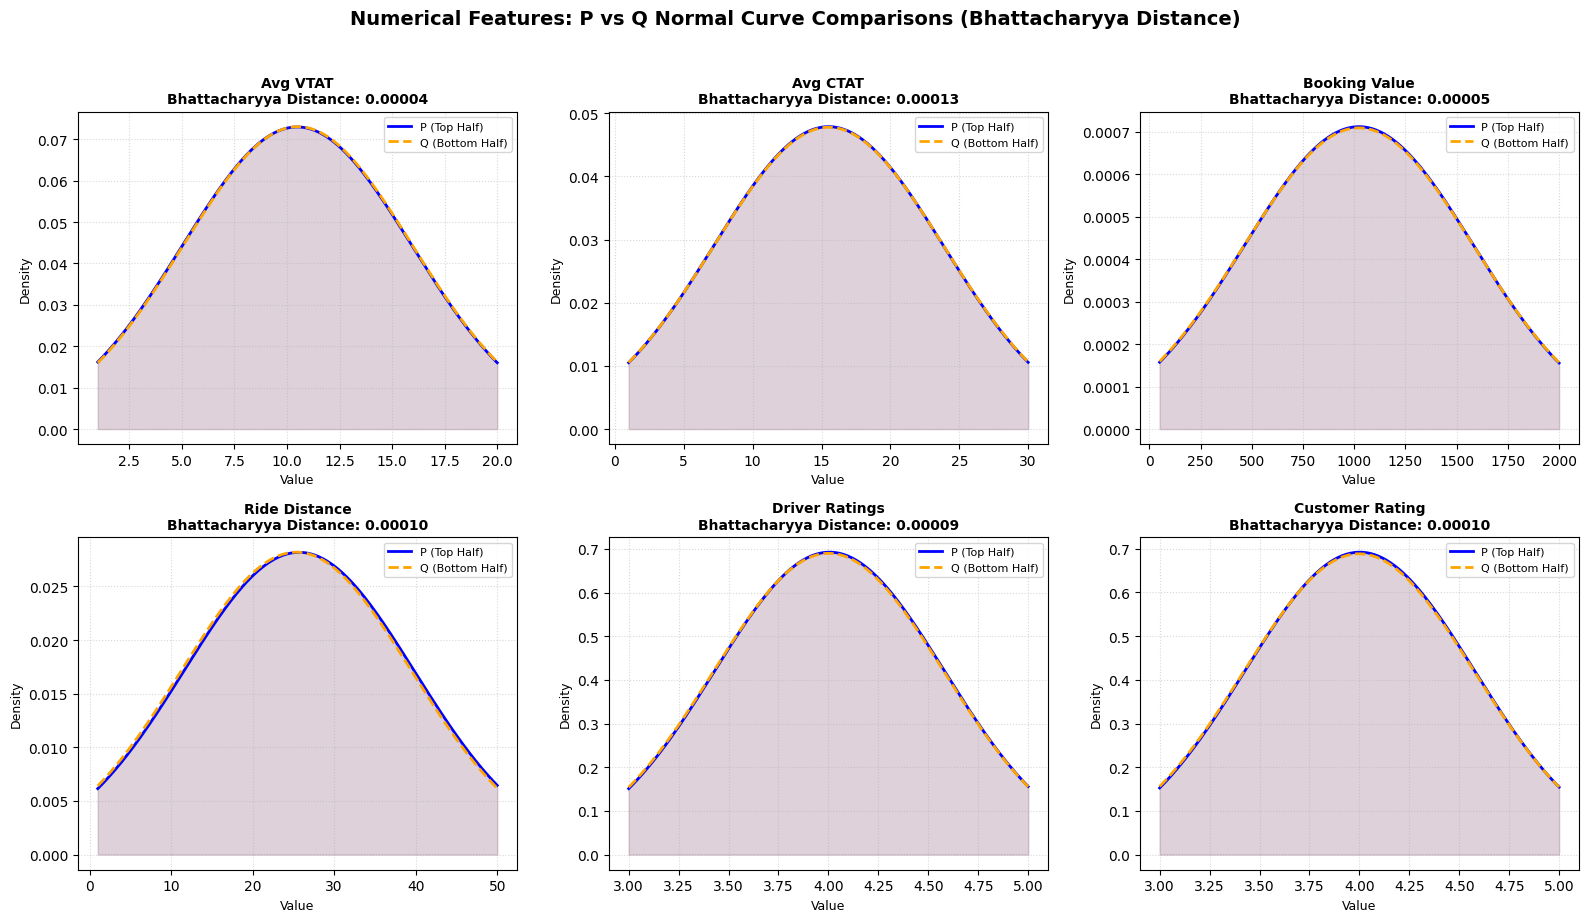

In [41]:
plot_numerical_bhattacharyya_curves(df_ola_cust_profile, num_cols, bins=10)

Conclusion: For the features the Bhattacharya distance ~ 0 hence there is no difference in data distribution between the top and the bottom half.

The outcome is similar to what we observed for KL Divergence

In [42]:
def plot_categorical_bhattacharyya_charts(df, cat_cols):
    """
    Sorts dataframe chronologically by time_col, splits horizontally into P (top half) and Q (bottom half),
    plots probability bar charts, and calculates the Bhattacharyya Distance for each categorical feature.
    """
    # Sort chronologically and split horizontally
    midpoint = len(df) // 2
    df_p = df.iloc[:midpoint]
    df_q = df.iloc[midpoint:]

    fig_cat, axes_cat = plt.subplots(len(cat_cols), 1, figsize=(10, 4 * len(cat_cols)))
    if len(cat_cols) == 1:
        axes_cat = [axes_cat]

    for i, col in enumerate(cat_cols):
        ax = axes_cat[i]
        if col not in df.columns:
            continue

        # Get normalized value counts
        p = df_p[col].value_counts(normalize=True)
        q = df_q[col].value_counts(normalize=True)

        # Align indexes so categories match side-by-side (missing ones fill with 0)
        p_df, q_df = p.align(q, fill_value=0)
        combined_df = pd.DataFrame({'P (Top)': p_df, 'Q (Bottom)': q_df})

        # Calculate Bhattacharyya Distance (Raw probabilities, no epsilon)
        p_vals = p_df.values
        q_vals = q_df.values

        bc = np.sum(np.sqrt(p_vals * q_vals))
        bc = max(bc, 1e-12)  # Safety floor to avoid log(0) = -inf
        bhatt_score = -np.log(bc)

        # Limit cardinality to top 10 categories if there are too many unique values (e.g., Locations)
        if len(combined_df) > 10:
            combined_df = combined_df.sort_values(by='P (Top)', ascending=False).head(10)

        combined_df.plot(kind='bar', ax=ax, width=0.7, color=['blue', 'orange'])

        # Title updated to reflect Bhattacharyya Distance
        ax.set_title(f"Categorical Feature: {col} | Bhattacharyya Distance: {bhatt_score:.5f}", fontsize=11, fontweight='bold')
        ax.set_ylabel('Probability Proportion', fontsize=9)
        ax.set_xlabel('Categories', fontsize=9)
        ax.tick_params(axis='x', rotation=30)
        ax.grid(axis='y', linestyle=':', alpha=0.5)
        ax.legend(loc='upper right', fontsize=9)

    plt.suptitle('Categorical Features: P vs Q Probability Distribution Shifts (Bhattacharyya Distance)', fontsize=14, fontweight='bold', y=1.01)
    plt.tight_layout()
    plt.savefig('categorical_features_bhattacharyya.png', dpi=300)
    plt.show()

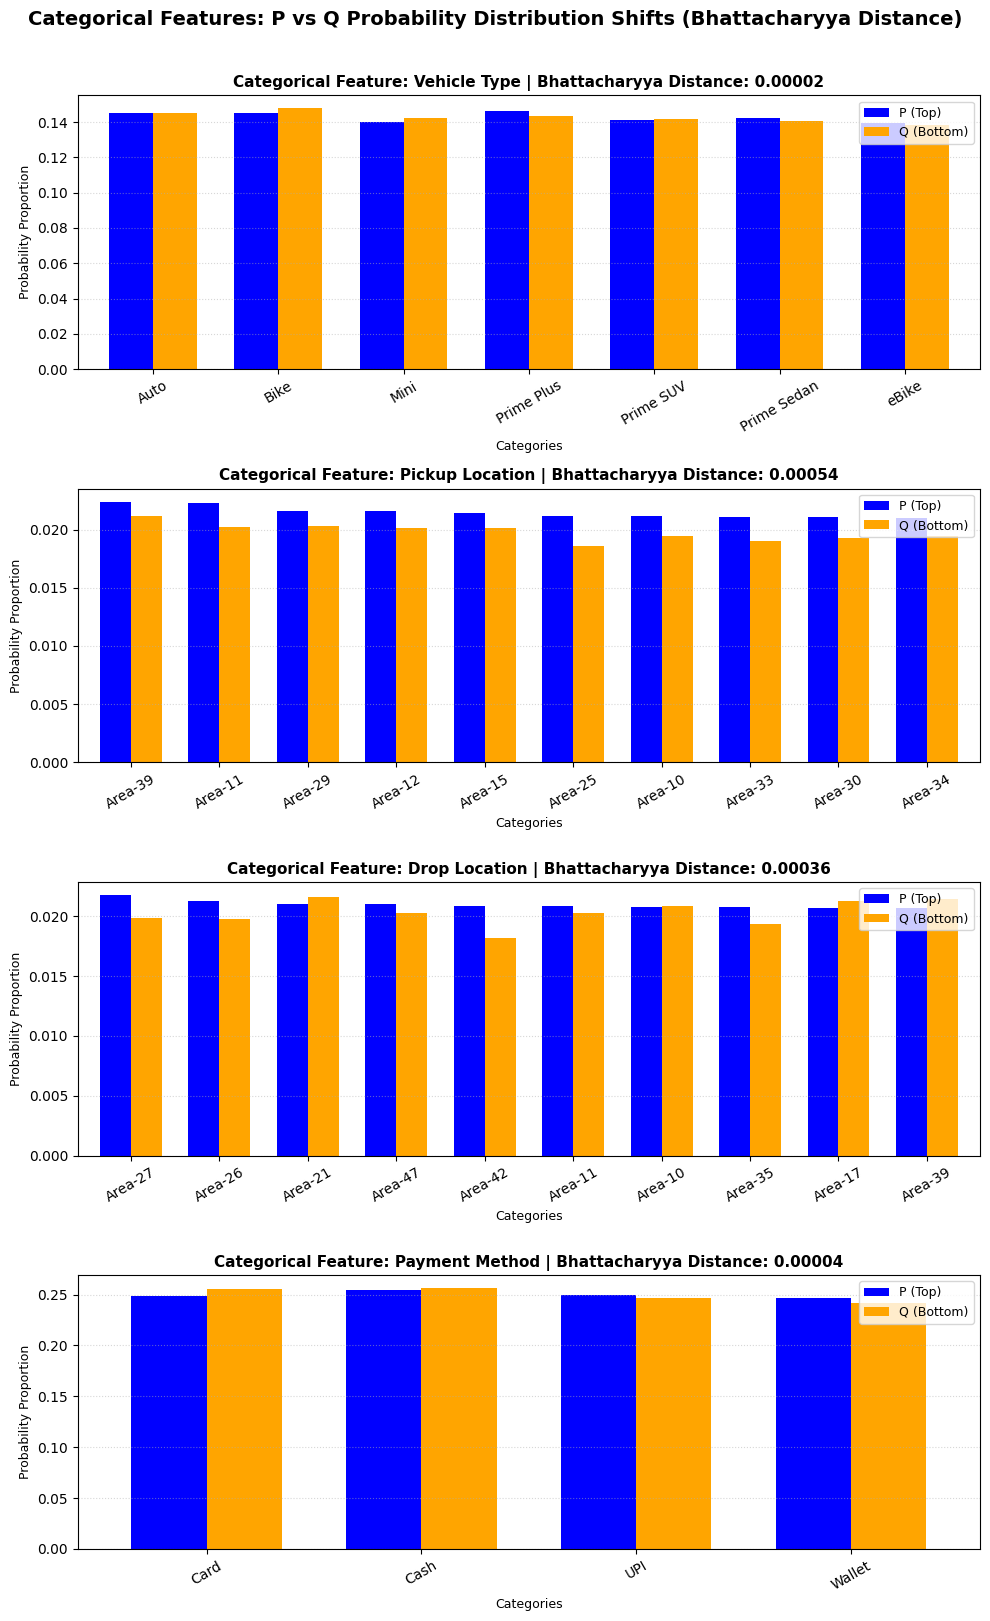

In [43]:
plot_categorical_bhattacharyya_charts(df_ola_cust_profile, cat_cols)

# End of Part 2